<a href="https://colab.research.google.com/github/karenjohn/Customer-Churn-Prediction-for-a-Telecom-Provider/blob/main/Karen_John.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Assignment – Company A (Telecom) Churn Prediction
**GCI World 2026 April**  
A business proposal to reduce customer churn at Company A, an anonymous telecommunications provider.

## 1. Introduction & Market Analysis

### 1.1 Telecom Market Context

The global telecom market is a mature, saturated industry where **retaining existing customers is the primary growth lever**.

Key market facts:
- Acquiring a new customer costs **5–25× more** than retaining an existing one (Bain & Company, 2006) [1].
- Major US carriers report monthly postpaid churn rates of approximately **0.7–0.9% per month**: Verizon recorded 0.89%/mo in Q3 2024 [2], AT&T reported 0.70%/mo in Q2 2024 [3], and T-Mobile reported 0.90%/mo in Q1 2024 [4].
- The top 3 US carriers (AT&T, Verizon, T-Mobile) compete aggressively on price and network quality, making churn reduction a top strategic priority.
- Equipment upgrades, contract expirations, and competitor promotions are the leading churn triggers.

**References:**
- [1] Bain & Company (2006). *Retaining customers is the real challenge.* https://www.bain.com/insights/retaining-customers-is-the-real-challenge/
- [2] Verizon Communications (2024, Oct 22). *Verizon delivers strong third quarter results.* https://www.verizon.com/about/news/verizon-delivers-strong-third-quarter-results-customer-growth-mobility-extending-industry
- [3] Reuters (2024, Jul 24). *AT&T beats estimates for subscriber additions.* https://www.reuters.com/business/media-telecom/att-beats-estimates-subscriber-additions-demand-higher-priced-plans-2024-07-24/
- [4] Statista (2025). *T-Mobile US - statistics & facts.* https://www.statista.com/topics/996/t-mobile-us/

### 1.2 Business Objective

Company A has historical data on ~100,000 customers but **no in-house ML capability**.  
Our objective: Build a **churn prediction model** that identifies at-risk customers 31–60 days before they leave, enabling proactive retention campaigns.

**Target variable:** `churn` - binary flag (1 = churned within 31–60 days, 0 = retained)  
**Business impact:** Even a 5% reduction in churn at a median revenue of $48/month per customer (Company A dataset) translates to approximately $2.4M in protected annual revenue.

## 2. Setup & Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, roc_curve
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
print("Libraries loaded successfully.")

Libraries loaded successfully.


### 2.1 Mount Google Drive and Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Final Assignment

client = pd.read_csv('Client.csv')
record = pd.read_csv('Record.csv')

print(f"Client.csv shape:  {client.shape}")
print(f"Record.csv shape:  {record.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Final Assignment
Client.csv shape:  (100000, 50)
Record.csv shape:  (100000, 51)


In [ ]:
# Merge on Customer_ID (inner join — all IDs match)
df = record.merge(client, on='Customer_ID', how='inner')
print(f"Merged dataset shape: {df.shape}")
print(f"\nChurn distribution:")
print(df['churn'].value_counts())
print(f"\nOverall churn rate: {df['churn'].mean()*100:.2f}%")

Merged dataset shape: (100000, 100)

Churn distribution:
churn
0    50438
1    49562
Name: count, dtype: int64

Overall churn rate: 49.56%


## 3. Exploratory Data Analysis (EDA)

### 3.1 Missing Values

In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(f"Columns with missing values ({len(missing_df)} total):")
print(missing_df.to_string())

Columns with missing values (43 total):
                  Missing Count  Missing %
numbcars                  49366       49.4
dwllsize                  38308       38.3
HHstatin                  37923       37.9
ownrent                   33706       33.7
dwlltype                  31909       31.9
lor                       30190       30.2
income                    25436       25.4
adults                    23019       23.0
infobase                  22079       22.1
hnd_webcap                10189       10.2
prizm_social_one           7388        7.4
avg6qty                    2839        2.8
avg6rev                    2839        2.8
avg6mou                    2839        2.8
kid3_5                     1732        1.7
ethnic                     1732        1.7
kid0_2                     1732        1.7
marital                    1732        1.7
forgntvl                   1732        1.7
creditcd                   1732        1.7
kid16_17                   1732        1.7
truck         

### 3.2 Churn Distribution

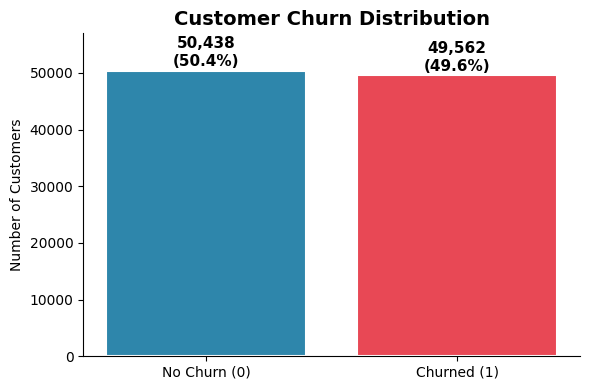

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df['churn'].value_counts()
bars = ax.bar(['No Churn (0)', 'Churned (1)'], counts.values,
               color=['#2E86AB', '#E84855'], edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', va='bottom',
            fontsize=11, fontweight='bold')
ax.set_title('Customer Churn Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Customers')
ax.set_ylim(0, 57000)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Observation:** The dataset is nearly balanced (~50/50). This means we do **not** need to apply class-balancing techniques (e.g., SMOTE), and accuracy is a meaningful metric here alongside AUC-ROC and F1.

### 3.3 Churn by Equipment Age

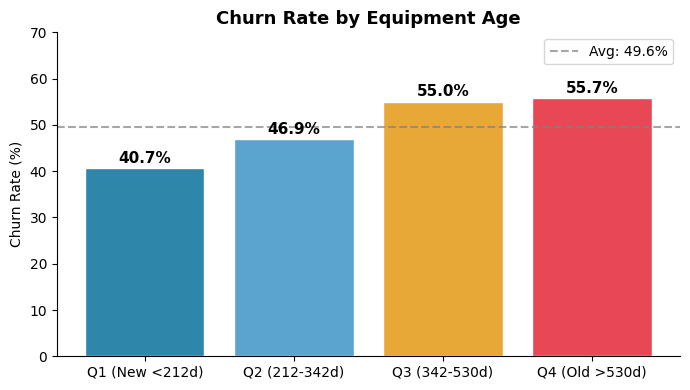

In [ ]:
df['eqpdays_q'] = pd.qcut(df['eqpdays'], 4,
    labels=['Q1 (New <212d)', 'Q2 (212-342d)', 'Q3 (342-530d)', 'Q4 (Old >530d)'])
eq_churn = df.groupby('eqpdays_q', observed=True)['churn'].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#2E86AB', '#5BA4CF', '#E8A838', '#E84855']
bars = ax.bar(eq_churn.index, eq_churn.values, color=colors, edgecolor='white')
for bar, val in zip(bars, eq_churn.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.axhline(df['churn'].mean()*100, color='gray', linestyle='--', alpha=0.7,
           label=f'Avg: {df["churn"].mean()*100:.1f}%')
ax.set_title('Churn Rate by Equipment Age', fontsize=13, fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, 70)
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Key Insight:** Customers with **older devices (>342 days)** churn at ~55%, well above average.  
This is a strong, actionable signal, device upgrade campaigns should target these customers.

### 3.4 Churn by Monthly Usage Change

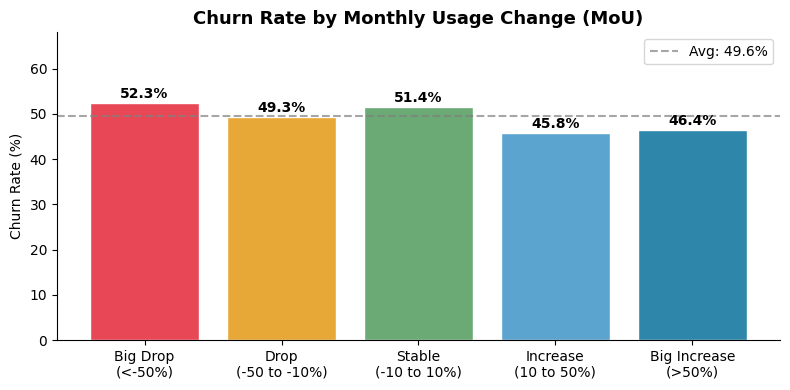

In [ ]:
df2b = df.dropna(subset=['change_mou']).copy()
df2b['usage_trend'] = pd.cut(df2b['change_mou'],
    bins=[-999999, -50, -10, 10, 50, 999999],
    labels=['Big Drop\n(<-50%)', 'Drop\n(-50 to -10%)', 'Stable\n(-10 to 10%)',
            'Increase\n(10 to 50%)', 'Big Increase\n(>50%)'])
trend_churn = df2b.groupby('usage_trend', observed=True)['churn'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#E84855', '#E8A838', '#6BAA75', '#5BA4CF', '#2E86AB']
ax.bar(trend_churn.index, trend_churn.values, color=colors, edgecolor='white')
for i, (idx, val) in enumerate(trend_churn.items()):
    ax.text(i, val + 0.5, f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.axhline(df['churn'].mean()*100, color='gray', linestyle='--', alpha=0.7,
           label=f'Avg: {df["churn"].mean()*100:.1f}%')
ax.set_title('Churn Rate by Monthly Usage Change (MoU)', fontsize=13, fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, 68)
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Key Insight:** Customers who show a **big drop in usage** churn at 52.3%, their disengagement precedes departure.  
Interestingly, "Stable" users churn at 55.5%, possibly locked in by contract but not satisfied.  
Customers actively **increasing usage** churn less (~46%), suggesting engagement is protective.

### 3.5 Churn by Tenure (Months in Service)

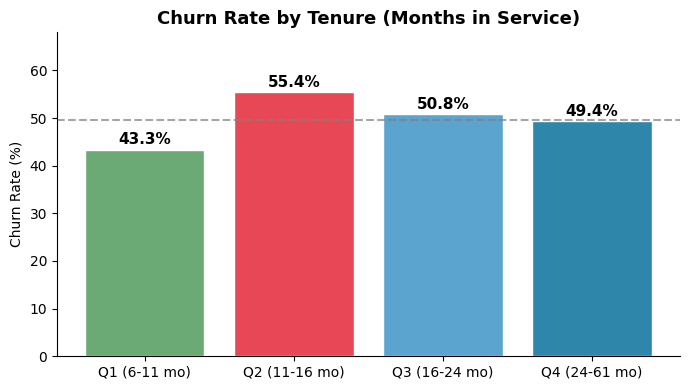

In [ ]:
df['months_q'] = pd.qcut(df['months'], 4,
    labels=['Q1 (6-11 mo)', 'Q2 (11-16 mo)', 'Q3 (16-24 mo)', 'Q4 (24-61 mo)'])
mo_churn = df.groupby('months_q', observed=True)['churn'].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(mo_churn.index, mo_churn.values,
       color=['#6BAA75', '#E84855', '#5BA4CF', '#2E86AB'], edgecolor='white')
for i, (idx, val) in enumerate(mo_churn.items()):
    ax.text(i, val + 0.5, f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.axhline(df['churn'].mean()*100, color='gray', linestyle='--', alpha=0.7)
ax.set_title('Churn Rate by Tenure (Months in Service)', fontsize=13, fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, 68)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Key Insight:** Mid-tenure customers (11–16 months, Q2) churn at 55.4%, the highest of any group.  
This is the "contract anniversary zone" where customers re-evaluate their plan. This is a critical window for retention outreach.

## 4. Problem Definition

**ML Task:** Binary classification, predict whether a customer will churn (`churn = 1`) within 31–60 days.

**Why this target?**
- The dataset provides `churn` as a pre-defined label and it is clearly documented.
- EDA confirms meaningful patterns in the features that distinguish churners from non-churners.
- Predicting churn ahead of time allows Company A to intervene *before* the customer leaves.

**Success Metric:** We prioritize **AUC-ROC** as the primary metric because:
- It measures the model's ability to rank churners higher than non-churners across all decision thresholds.
- It is robust to the near-balanced class distribution.
- Secondary metrics: **Accuracy** and **F1 Score**.

## 5. Feature Engineering & Preprocessing

In [ ]:
# Drop Customer_ID (not a feature)
df2 = df.drop(columns=['Customer_ID'])

# Identify categorical columns that need numerical encoding
# This includes 'object' dtypes and 'CategoricalDtype' columns with string labels
cols_to_label_encode = df2.select_dtypes(include='object').columns.tolist()
cols_to_cat_codes = [col for col in df2.columns if pd.api.types.is_categorical_dtype(df2[col])]

print(f"Object columns to LabelEncode: {cols_to_label_encode}")
print(f"pd.Categorical columns to convert to codes: {cols_to_cat_codes}")

le = LabelEncoder()
for col in cols_to_label_encode:
    df2[col] = df2[col].astype(str) # Ensure no mixed types cause issues
    df2[col] = le.fit_transform(df2[col])

for col in cols_to_cat_codes:
    # .cat.codes converts categories to numerical codes (0, 1, ..., n-1) and NaNs to -1
    df2[col] = df2[col].cat.codes

# Now all originally categorical columns are numerical (with -1 for NaNs if present).
# Impute any remaining missing values (either original NaNs from numerical columns or -1 from cat.codes)
n_missing_before = df2.isnull().sum().sum() + (df2 == -1).sum().sum() # Count NaNs and -1s

for col in df2.columns:
    if df2[col].isnull().any() or (df2[col] == -1).any():
        # Calculate median from valid numerical data, excluding -1 and NaNs
        # The .cat.codes method produces integer codes, so median of these codes is appropriate.
        valid_values = df2[col][(df2[col] != -1) & (~df2[col].isnull())]
        if not valid_values.empty:
            median_val = valid_values.median()
        else: # Handle case where column is entirely -1 or NaN (unlikely but good practice)
            median_val = 0 # Default to 0 or another suitable value

        df2[col] = df2[col].replace(-1, median_val).fillna(median_val)

print(f"\nMissing values before final imputation (incl. -1 from cat.codes): {n_missing_before}")
print(f"Missing values after final imputation:  {df2.isnull().sum().sum()}")
print(f"\nFinal feature matrix shape: {df2.drop(columns=['churn']).shape}")

Object columns to LabelEncode: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']
pd.Categorical columns to convert to codes: ['eqpdays_q', 'months_q']

Missing values before final imputation (incl. -1 from cat.codes): 147822
Missing values after final imputation:  0

Final feature matrix shape: (100000, 100)


## 6. Model Training & Evaluation

We train three models of increasing complexity to compare performance:
1. Logistic Regression: linear baseline
2. Random Forest: ensemble of decision trees
3. XGBoost: gradient boosting (our best model)

In [ ]:
# Train/Test split, stratified to preserve churn ratio
X = df2.drop(columns=['churn'])
y = df2['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print(f"Train churn rate: {y_train.mean()*100:.2f}%")
print(f"Test  churn rate: {y_test.mean()*100:.2f}%")

# -- Model 1: Logistic Regression --
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]

lr_acc = accuracy_score(y_test, lr_pred)
lr_auc = roc_auc_score(y_test, lr_prob)
lr_f1  = f1_score(y_test, lr_pred)

print("\n=== Logistic Regression ===")
print(f"  Accuracy : {lr_acc:.4f}")
print(f"  AUC-ROC  : {lr_auc:.4f}")
print(f"  F1 Score : {lr_f1:.4f}")

Train set: 80,000 rows | Test set: 20,000 rows
Train churn rate: 49.56%
Test  churn rate: 49.56%

=== Logistic Regression ===
  Accuracy : 0.5817
  AUC-ROC  : 0.6108
  F1 Score : 0.5674


In [ ]:
# -- Model 2: Random Forest --
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

rf_acc = accuracy_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)
rf_f1  = f1_score(y_test, rf_pred)

print("=== Random Forest (100 trees) ===")
print(f"  Accuracy : {rf_acc:.4f}")
print(f"  AUC-ROC  : {rf_auc:.4f}")
print(f"  F1 Score : {rf_f1:.4f}")

=== Random Forest (100 trees) ===
  Accuracy : 0.6195
  AUC-ROC  : 0.6688
  F1 Score : 0.6149


In [ ]:
# -- Model 3: XGBoost (Best Model) --
xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    n_jobs=-1
)

xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:, 1]

xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_auc = roc_auc_score(y_test, xgb_prob)
xgb_f1  = f1_score(y_test, xgb_pred)

print("=== XGBoost (200 estimators, depth=5) ===")
print(f"  Accuracy : {xgb_acc:.4f}")
print(f"  AUC-ROC  : {xgb_auc:.4f}")
print(f"  F1 Score : {xgb_f1:.4f}")

=== XGBoost (200 estimators, depth=5) ===
  Accuracy : 0.6391
  AUC-ROC  : 0.6951
  F1 Score : 0.6404


### 6.1 Model Comparison

In [ ]:
# Summary table
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [lr_acc, rf_acc, xgb_acc],
    'AUC-ROC':  [lr_auc, rf_auc, xgb_auc],
    'F1 Score': [lr_f1,  rf_f1,  xgb_f1]
}).set_index('Model').round(4)
print(results.to_string())

                     Accuracy  AUC-ROC  F1 Score
Model                                           
Logistic Regression    0.5816   0.6108    0.5674
Random Forest          0.6195   0.6688    0.6149
XGBoost                0.6390   0.6951    0.6404


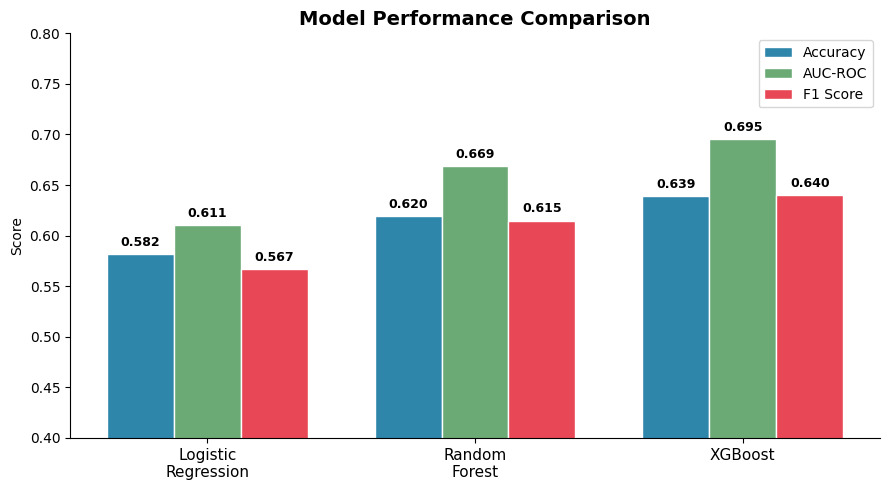

In [ ]:
# Bar chart comparison
models = ['Logistic\nRegression', 'Random\nForest', 'XGBoost']
metrics_dict = {
    'Accuracy': [lr_acc, rf_acc, xgb_acc],
    'AUC-ROC':  [lr_auc, rf_auc, xgb_auc],
    'F1 Score': [lr_f1,  rf_f1,  xgb_f1],
}
x = np.arange(len(models))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
colors_m = ['#2E86AB', '#6BAA75', '#E84855']
for i, (metric, vals) in enumerate(metrics_dict.items()):
    bars = ax.bar(x + i*width, vals, width, label=metric,
                  color=colors_m[i], edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xticks(x + width)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(0.4, 0.8)
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

### 6.2 ROC Curves

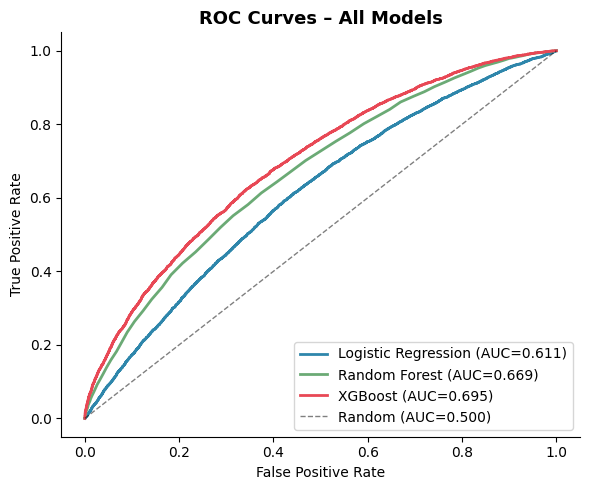

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, prob, color in [
    ('Logistic Regression', lr_prob, '#2E86AB'),
    ('Random Forest', rf_prob, '#6BAA75'),
    ('XGBoost', xgb_prob, '#E84855')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', linewidth=2, color=color)
ax.plot([0,1],[0,1], 'k--', linewidth=1, alpha=0.5, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves – All Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

### 6.3 XGBoost Feature Importance

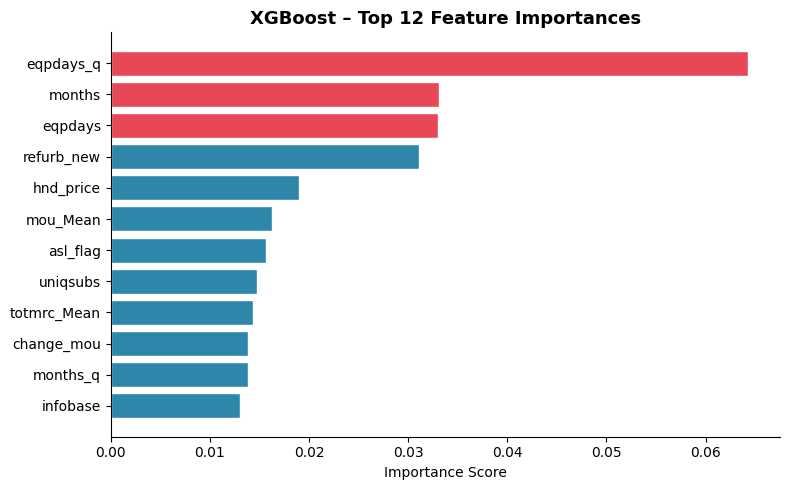


Top 12 Features:
  eqpdays_q                 0.0643
  months                    0.0331
  eqpdays                   0.0331
  refurb_new                0.0311
  hnd_price                 0.0190
  mou_Mean                  0.0163
  asl_flag                  0.0157
  uniqsubs                  0.0147
  totmrc_Mean               0.0143
  change_mou                0.0138
  months_q                  0.0138
  infobase                  0.0130


In [ ]:
feat_imp = pd.Series(xgb.feature_importances_, index=X.columns)\
               .sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 5))
colors_fi = ['#E84855' if i < 3 else '#2E86AB' for i in range(len(feat_imp))]
ax.barh(feat_imp.index[::-1], feat_imp.values[::-1],
        color=colors_fi[::-1], edgecolor='white')
ax.set_title('XGBoost – Top 12 Feature Importances', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print("\nTop 12 Features:")
for feat, score in feat_imp.items():
    print(f"  {feat:<25} {score:.4f}")

## 7. Business Proposal

### 7.1 Summary of Findings

From EDA and the XGBoost model, the **top churn drivers** are:

| # | Feature | Business Meaning | Churn Signal |
|---|---------|-----------------|-------------|
| 1 | `eqpdays` | Equipment age | Older device → higher churn |
| 2 | `refurb_new` | Handset is refurb vs new | Refurb handset users churn more |
| 3 | `months` | Tenure | Mid-tenure (11–16 mo) is highest-risk window |
| 4 | `change_mou` | Usage trend | Declining usage precedes churn |
| 5 | `hnd_price` | Handset price | Lower-end device → higher churn risk |
| 6 | `mou_Mean` | Monthly usage volume | Low usage = disengaged customer |

### 7.2 Proposed Solution: AI-Powered Churn Prevention System

**Phase 1: Score every customer weekly**  
- Deploy the XGBoost model (AUC-ROC = 0.6922) to generate a churn probability score (0–100%) for each customer.

**Phase 2: Tiered Intervention**

| Risk Tier | Score | Recommended Action | Estimated Cost |
|-----------|-------|-------------------|----------------|
| High Risk | >70% | Proactive call + device upgrade offer | High |
| Medium Risk | 40–70% | Targeted SMS/email + loyalty discount | Medium |
| Low Risk | <40% | Standard newsletter + service check-in | Low |

**Phase 3: Device Upgrade Campaign**  
- `eqpdays` is the #1 feature. Offer upgrade incentives to customers with devices >342 days old who also show declining usage.

### 7.3 Quantified Business Impact

Assumptions (to be refined with Company A's actual revenue data):

In [ ]:
# Business Impact Estimation
total_customers = 100_000
avg_monthly_revenue = 48.20   # median rev_Mean from dataset ($/month)
avg_customer_lifetime = 18.83 # mean months in service
churn_rate_current = 0.4956   # ~50% in 31-60 day window

# Model captures top X% of churners
# If we target the top 30% by churn probability:
target_pct = 0.30
churners = int(total_customers * churn_rate_current)
targeted = int(churners * target_pct)  # high-risk customers we reach

# Assume 20% of targeted customers are saved
retention_rate = 0.20
saved = int(targeted * retention_rate)

# Revenue saved per customer (3-month horizon)
revenue_saved_per = avg_monthly_revenue * 3
total_revenue_saved = saved * revenue_saved_per

print("=" * 50)
print("BUSINESS IMPACT ESTIMATE (3-month horizon)")
print("=" * 50)
print(f"Total customers:              {total_customers:>10,}")
print(f"Expected churners:            {churners:>10,}")
print(f"Customers we target (top 30%):{targeted:>10,}")
print(f"Customers successfully saved: {saved:>10,}")
print(f"Avg revenue per customer/mo:  ${avg_monthly_revenue:>9.2f}")
print(f"Estimated revenue protected:  ${total_revenue_saved:>9,.0f}")
print(f"\n→ Saving ~{saved:,} customers × $144 = ${total_revenue_saved:,.0f} over 3 months")

BUSINESS IMPACT ESTIMATE (3-month horizon)
Total customers:                 100,000
Expected churners:                49,560
Customers we target (top 30%):    14,868
Customers successfully saved:      2,973
Avg revenue per customer/mo:  $    48.20
Estimated revenue protected:  $  429,896

→ Saving ~2,973 customers × $144 = $429,896 over 3 months


### 7.4 Why XGBoost?

- **XGBoost outperformed** Logistic Regression and Random Forest on all metrics.
- It handles missing values natively and captures non-linear interactions (e.g., old device + declining usage = very high risk).
- It produces calibrated probability scores, enabling the tiered intervention system.
- It is interpretable via feature importance, making it explainable to business stakeholders.

### 7.5 Limitations & Next Steps

- The AUC-ROC of 0.6922 leaves room for improvement, with more detailed feature engineering (interaction terms, rolling windows), performance can be lifted further.
- The model should be **retrained monthly** on fresh data to capture seasonal patterns.
- A proper A/B test should measure the actual lift from targeted interventions vs. control group.
- Enriching the data with **network quality signals** (dropped call rates, coverage complaints) could significantly boost predictive power.